# Analyse exploratoire — Agriculture CropYield

Premier des deux jeux fournis. Il décrit des **parcelles** : sol, pluie, température,
fertilisation, irrigation, météo, durée de cycle et rendement obtenu. Ce sont les
variables qu'un agriculteur pourra renseigner dans l'application.

Objectif de ce notebook : **constater**, pas trancher. Les décisions de nettoyage sont
listées en conclusion et appliquées plus tard, dans le notebook 06 — une variable ne
s'écarte qu'une fois son absence d'intérêt établie.

# Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from src import config, utils
from src.data import preparation

utils.style()
np.random.seed(config.SEED)

# Lecture du dataset

In [2]:
# Raw read: booleans stay as text and nothing is filtered, so that
# the analysis can observe the actual state of the file.
df = preparation.charge()
print(f"{df.shape[0]:,} lignes x {df.shape[1]} colonnes")
df.head()

1,000,000 lignes x 10 colonnes


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [3]:
utils.profil(df, "A")

,type,manquantes,manquantes_%,valeurs_uniques,exemple
colonne A,,,,,
Region,category,0,0.0,4,West
Soil_Type,category,0,0.0,6,Sandy
Crop,category,0,0.0,6,Cotton
Rainfall_mm,float64,0,0.0,1000000,897.077239
Temperature_Celsius,float64,0,0.0,1000000,27.676966
Fertilizer_Used,bool,0,0.0,2,False
Irrigation_Used,bool,0,0.0,2,True
Weather_Condition,category,0,0.0,3,Cloudy
Days_to_Harvest,int16,0,0.0,90,122


**Observations :**

- **Aucune valeur manquante**, sur aucune colonne.
- Deux colonnes booléennes sont stockées en texte (`'True'` / `'False'`) : à convertir.
- Quatre variables nominales, trois continues, une entière, et la cible.

# Statistiques basiques

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,1000000.0,549.981901,259.851320,100.000896,324.891090,550.124061,774.738520,999.998098
Temperature_Celsius,1000000.0,27.504965,7.220608,15.000034,21.254502,27.507365,33.753267,39.999997
Days_to_Harvest,1000000.0,104.495025,25.953412,60.000000,82.000000,104.000000,127.000000,149.000000
Yield_tons_per_hectare,1000000.0,4.649472,1.696572,-1.147613,3.417637,4.651808,5.879200,9.963372


In [5]:
print(f"doublons stricts : {df.duplicated().sum()}")
print()
for colonne in preparation.COLONNES_CATEGORIELLES + preparation.COLONNES_BOOLEENNES:
    effectifs = df[colonne].value_counts()
    print(f"{colonne:20s} {len(effectifs):2d} modalités | "
          f"part min {effectifs.min()/len(df):.3f} — max {effectifs.max()/len(df):.3f}")

doublons stricts : 0

Region                4 modalités | part min 0.250 — max 0.250
Soil_Type             6 modalités | part min 0.166 — max 0.167
Crop                  6 modalités | part min 0.166 — max 0.167
Weather_Condition     3 modalités | part min 0.333 — max 0.334
Fertilizer_Used       2 modalités | part min 0.500 — max 0.500
Irrigation_Used       2 modalités | part min 0.499 — max 0.501


**Observations :**

- Aucun doublon strict sur un million de lignes.
- Toutes les modalités sont réparties à parts quasi égales : écart de 0,1 point entre la
  plus et la moins fréquente. Une telle régularité ne s'observe pas sur des relevés de
  terrain — **le jeu est simulé**.

# Variables numériques

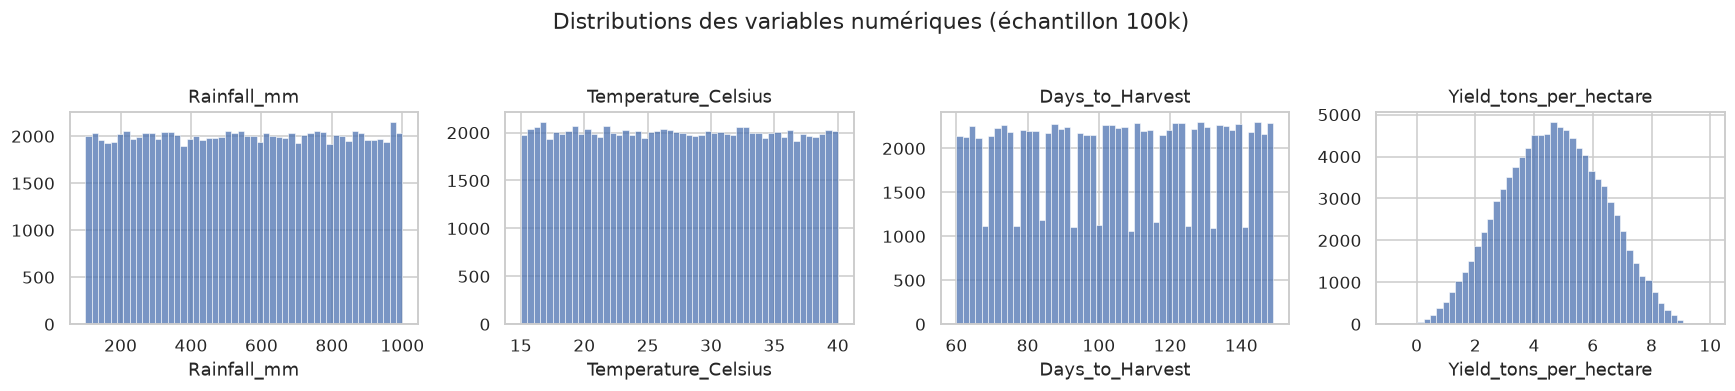

In [6]:
echantillon = df.sample(utils.ECHANTILLON_FIGURES, random_state=config.SEED)
continues = list(preparation.COLONNES_CONTINUES) + [preparation.CIBLE]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, colonne in zip(axes, continues):
    sns.histplot(echantillon[colonne], bins=50, ax=ax, color="#4C72B0")
    ax.set_title(colonne)
    ax.set_ylabel("")
fig.suptitle("Distributions des variables numériques (échantillon 100k)", y=1.04)
utils.enregistre("01_distributions_numeriques")
plt.show()

**Observations :**

- Pluie, température et durée de cycle sont **uniformes** sur toute leur plage : encore
  une signature de génération artificielle.
- Seule la cible est en cloche, ce qui est cohérent avec une somme d'effets additifs
  bruitée.

## Outliers

In [7]:
bornes = pd.DataFrame({
    "min": df[continues].min(),
    "max": df[continues].max(),
    "q1": df[continues].quantile(0.25),
    "q3": df[continues].quantile(0.75),
})
bornes["iqr"] = bornes["q3"] - bornes["q1"]
bornes["hors 1.5 IQR"] = [
    int(((df[c] < bornes.loc[c, "q1"] - 1.5 * bornes.loc[c, "iqr"]) |
         (df[c] > bornes.loc[c, "q3"] + 1.5 * bornes.loc[c, "iqr"])).sum())
    for c in continues
]
bornes.round(3)

,min,max,q1,q3,iqr,hors 1.5 IQR
Rainfall_mm,100.001,999.998,324.891,774.739,449.847,0
Temperature_Celsius,15.000,40.000,21.255,33.753,12.499,0
Days_to_Harvest,60.000,149.000,82.000,127.000,45.000,0
Yield_tons_per_hectare,-1.148,9.963,3.418,5.879,2.462,84


**Observations :**

- Les trois variables explicatives sont bornées par construction (pluie 100-1000 mm,
  température 15-40 °C, cycle 60-150 jours) : aucun outlier n'est possible.
- Le seul point de vigilance porte sur la cible, examinée ci-dessous.

## Cible

In [8]:
negatifs = df[df[preparation.CIBLE] < 0]
print(f"rendements négatifs : {len(negatifs)} ({len(negatifs)/len(df):.4%})")
print(f"plage : {negatifs[preparation.CIBLE].min():.3f} à "
      f"{negatifs[preparation.CIBLE].max():.3f} t/ha")
print()
print("conditions de ces parcelles :")
print(f"  sans engrais     : {(~negatifs['Fertilizer_Used'].astype(str).eq('True')).sum()} / {len(negatifs)}")
print(f"  sans irrigation  : {(~negatifs['Irrigation_Used'].astype(str).eq('True')).sum()} / {len(negatifs)}")
print(f"  pluie < 200 mm   : {(negatifs['Rainfall_mm'] < 200).sum()} / {len(negatifs)}")
negatifs.head(3)

rendements négatifs : 231 (0.0231%)
plage : -1.148 à -0.000 t/ha

conditions de ces parcelles :
  sans engrais     : 231 / 231
  sans irrigation  : 231 / 231
  pluie < 200 mm   : 223 / 231


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
756,East,Peaty,Cotton,101.019421,33.804131,False,False,Rainy,117,-0.007103
7799,South,Chalky,Rice,108.804894,18.004082,False,False,Sunny,86,-0.061283
8421,East,Chalky,Soybean,168.120735,38.473430,False,False,Cloudy,111,-0.119911


**Observations :**

- 231 parcelles affichent un rendement **négatif**, ce qui n'existe pas.
- Elles sont **toutes sans engrais ni irrigation**, et 223 sur 231 sous 200 mm de pluie :
  il s'agit du bruit additif du générateur passant sous zéro dans les conditions les
  plus défavorables, et non d'une erreur de saisie dispersée.
- Décision différée en conclusion.

## Corrélations

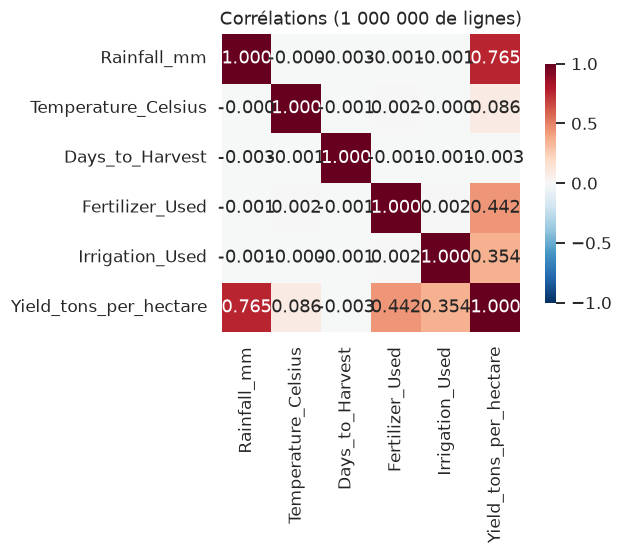

,r,r²,part de la variance
Rainfall_mm,0.765,0.585,58.5%
Fertilizer_Used,0.442,0.195,19.5%
Irrigation_Used,0.354,0.125,12.5%
Temperature_Celsius,0.086,0.007,0.7%
Days_to_Harvest,-0.003,0.000,0.0%


In [9]:
numerique = preparation.typage(df)[list(preparation.COLONNES_CONTINUES) +
                                   list(preparation.COLONNES_BOOLEENNES) +
                                   [preparation.CIBLE]].astype(float)
correlations = numerique.corr()

fig, ax = plt.subplots(figsize=(6.6, 5.2))
sns.heatmap(correlations, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Corrélations (1 000 000 de lignes)")
utils.enregistre("01_correlations")
plt.show()

# Une corrélation seule se lit mal : r² dit quelle part de la variance elle représente.
liens = correlations[preparation.CIBLE].drop(preparation.CIBLE).sort_values(key=abs, ascending=False)
pd.DataFrame({"r": liens.round(3), "r²": (liens**2).round(3),
              "part de la variance": (liens**2).map("{:.1%}".format)})

In [10]:
# Pour une variable binaire, la corrélation n'est pas la bonne mesure : elle dépend de
# l'équilibre des deux groupes. L'effet en t/ha, lui, se lit directement.
typé = preparation.typage(df)
lignes = []
for levier in preparation.COLONNES_BOOLEENNES:
    sans, avec = typé.loc[~typé[levier], preparation.CIBLE], typé.loc[typé[levier], preparation.CIBLE]
    effet = avec.mean() - sans.mean()
    # d de Cohen : l'effet exprimé en écarts-types intra-groupe
    sd_intra = np.sqrt(((len(sans) - 1) * sans.var() + (len(avec) - 1) * avec.var())
                       / (len(sans) + len(avec) - 2))
    r = typé[levier].astype(float).corr(typé[preparation.CIBLE])
    lignes.append({"levier": levier, "effet (t/ha)": round(effet, 3),
                   "r": round(r, 3), "r²": round(r**2, 3),
                   "d de Cohen": round(effet / sd_intra, 2)})
pd.DataFrame(lignes).set_index("levier")

,effet (t/ha),r,r²,d de Cohen
levier,,,,
Fertilizer_Used,1.5,0.442,0.195,0.99
Irrigation_Used,1.2,0.354,0.125,0.76


**Observations :**

| Variable | r | Part de la variance | Lecture |
|---|---|---|---|
| `Rainfall_mm` | **0,765** | **58,5 %** | facteur dominant |
| `Fertilizer_Used` | 0,442 | 19,5 % | corrélation **modérée**, mais effet important — voir ci-dessous |
| `Irrigation_Used` | 0,354 | 12,5 % | corrélation **modérée**, idem |
| `Temperature_Celsius` | 0,086 | 0,7 % | faible — examiné par tranches ci-dessous |
| `Days_to_Harvest` | −0,004 | 0,0 % | aucune relation linéaire |

- Seule la pluie entretient une relation **forte** avec le rendement : elle en explique à
  elle seule 58,5 % de la variance. Les deux leviers agricoles sont nettement en dessous,
  à 19,5 % et 12,5 %.

- **Mais une corrélation se lit mal pour une variable binaire**, et le tableau ci-dessus le
  montre. L'engrais apporte **+1,50 t/ha**, soit une différence de **~1,0 écart-type** entre
  parcelles fertilisées et non fertilisées — un effet important au sens usuel. Sa corrélation
  reste pourtant à 0,44, parce que le coefficient dépend aussi de l'équilibre des deux
  groupes : à 50/50, il vaut environ la moitié de l'effet exprimé en écarts-types.

  Autrement dit, **la corrélation sous-estime l'importance pratique d'un levier binaire**.
  Pour l'engrais et l'irrigation, la mesure à retenir est l'effet en t/ha, pas le `r`.

- Les corrélations **entre variables explicatives** sont toutes nulles : elles sont
  mutuellement indépendantes. C'est ce que l'ACP du notebook 02 va confirmer.

## Température

In [11]:
# A weak correlation can hide a non-linear relationship: we look at it by bins.
par_tranche = df.groupby(pd.cut(df["Temperature_Celsius"], bins=10),
                         observed=True)[preparation.CIBLE].mean()
print(par_tranche.round(3).to_string())
print(f"\namplitude entre la première et la dernière tranche : "
      f"{par_tranche.iloc[-1] - par_tranche.iloc[0]:+.3f} t/ha")
print(f"progression strictement croissante : {par_tranche.is_monotonic_increasing}")

Temperature_Celsius
(14.975, 17.5]    4.423
(17.5, 20.0]      4.473
(20.0, 22.5]      4.525
(22.5, 25.0]      4.571
(25.0, 27.5]      4.626
(27.5, 30.0]      4.681
(30.0, 32.5]      4.717
(32.5, 35.0]      4.775
(35.0, 37.5]      4.835
(37.5, 40.0]      4.867

amplitude entre la première et la dernière tranche : +0.445 t/ha
progression strictement croissante : True


**Observations :**

- Le rendement moyen progresse de **+0,445 t/ha** entre la tranche la plus froide et la
  plus chaude, **sans aucune exception** dans la progression.
- L'effet est donc **faible au regard de la variabilité totale, mais parfaitement
  systématique**. Une corrélation de 0,09 aurait conduit à l'écarter à tort.

## Days_to_Harvest

In [12]:
par_tranche = df.groupby(pd.cut(df["Days_to_Harvest"], bins=9),
                         observed=True)[preparation.CIBLE].mean()
print(par_tranche.round(3).to_string())
print(f"\namplitude entre tranches : "
      f"{par_tranche.max() - par_tranche.min():.3f} t/ha")

Days_to_Harvest
(59.911, 69.889]      4.663
(69.889, 79.778]      4.654
(79.778, 89.667]      4.651
(89.667, 99.556]      4.653
(99.556, 109.444]     4.644
(109.444, 119.333]    4.635
(119.333, 129.222]    4.649
(129.222, 139.111]    4.650
(139.111, 149.0]      4.646

amplitude entre tranches : 0.028 t/ha


**Observations :**

- Ni relation linéaire (corrélation −0,004), ni relation par tranches : **0,028 t/ha**
  d'amplitude, soit du bruit.
- La durée du cycle ne porte aucune information sur le rendement dans ce jeu.

## Interactions simples

Des moyennes identiques entre cultures ne suffisent pas à conclure : une culture pourrait
être médiocre en moyenne et excellente sous irrigation. On vérifie donc les effets **à
conditions comparables**, et on exprime l'écart en t/ha — avec un million de lignes, tout
test est significatif, seule l'ampleur compte.

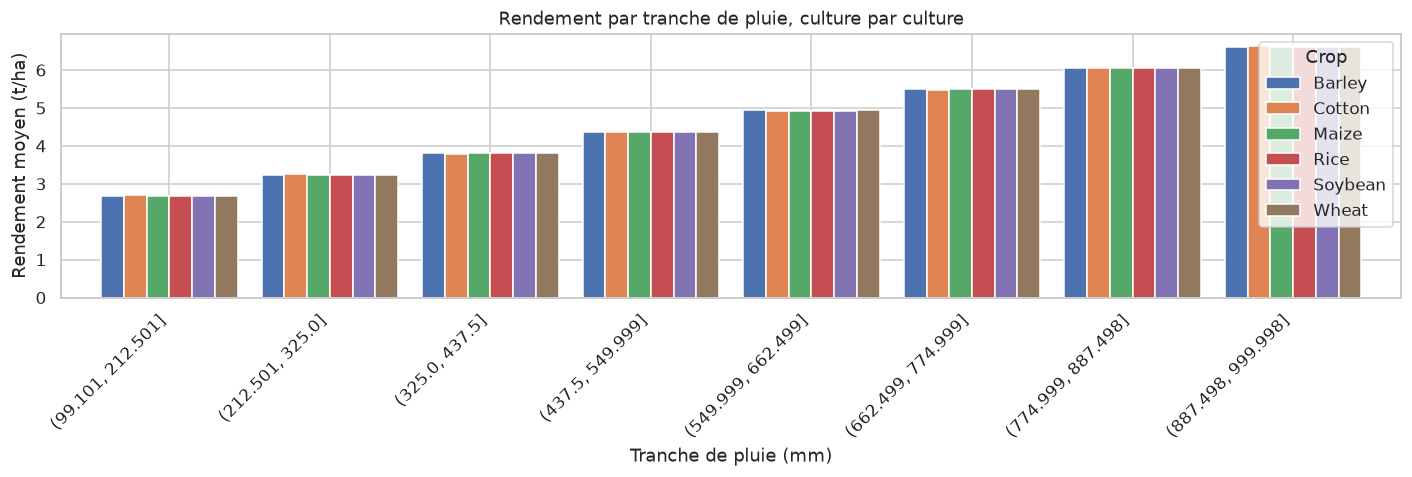

écart maximum entre cultures, à pluie comparable : 0.0280 t/ha


In [13]:
# Is the rainfall -> yield relationship the same for every crop?
par_pluie = utils.ecart_par_groupe(df, "Crop", preparation.CIBLE, bornes="Rainfall_mm")

ax = par_pluie.drop(columns="ecart max").plot(kind="bar", figsize=(13, 4.5), width=0.85)
ax.set_xlabel("Tranche de pluie (mm)")
ax.set_ylabel("Rendement moyen (t/ha)")
ax.set_title("Rendement par tranche de pluie, culture par culture")
plt.xticks(rotation=45, ha="right")
utils.enregistre("01_interaction_pluie_culture")
plt.show()

print(f"écart maximum entre cultures, à pluie comparable : "
      f"{par_pluie['ecart max'].max():.4f} t/ha")

In [14]:
# Is the effect of the levers the same for every crop?
for levier in preparation.COLONNES_BOOLEENNES:
    table = utils.effet_levier(preparation.typage(df), levier, "Crop", preparation.CIBLE)
    print(f"-- {levier}")
    print(table.to_string())
    print(f"   variation de l'effet entre cultures : {table.attrs['variation']:.4f} t/ha\n")

-- Fertilizer_Used
Fertilizer_Used   False    True   effet
Crop                                   
Barley           3.8914  5.4056  1.5142
Cotton           3.9022  5.3977  1.4955
Maize            3.8968  5.3906  1.4937
Rice             3.8998  5.4005  1.5007
Soybean          3.9063  5.4018  1.4955
Wheat            3.9005  5.4015  1.5010
   variation de l'effet entre cultures : 0.0205 t/ha

-- Irrigation_Used
Irrigation_Used   False    True   effet
Crop                                   
Barley           4.0512  5.2448  1.1936
Cotton           4.0523  5.2505  1.1982
Maize            4.0383  5.2446  1.2063
Rice             4.0524  5.2578  1.2053
Soybean          4.0481  5.2574  1.2093
Wheat            4.0572  5.2464  1.1892
   variation de l'effet entre cultures : 0.0201 t/ha



**Observations :**

- À pluie comparable, les six cultures donnent le même rendement à **0,028 t/ha** près.
- L'effet de l'engrais varie de **+1,494 à +1,514 t/ha** selon la culture, celui de
  l'irrigation de **+1,189 à +1,209** : environ 0,02 t/ha de variation, soit rien.
- **Aucune interaction notable sur les croisements examinés.** Les cultures restent
  équivalentes à conditions égales, et pas seulement en moyenne.
- Point décisif pour la suite : `/recommend` doit classer les cultures, or rien ici ne
  permet de les départager. À confronter au second jeu de données.

# Variables booléennes

Fertilizer_Used    sans 3.900 | avec 5.400 | effet +1.500 t/ha
Irrigation_Used    sans 4.050 | avec 5.250 | effet +1.200 t/ha


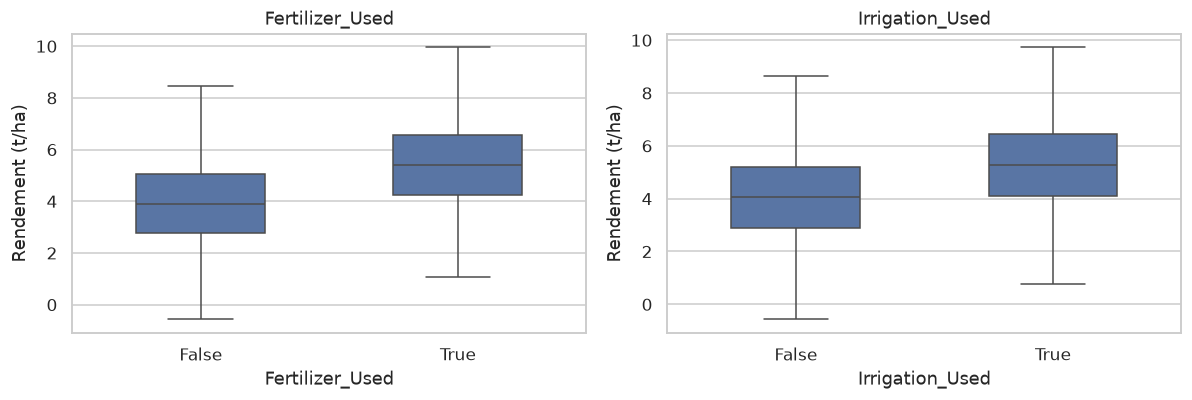

In [15]:
typé = preparation.typage(df)
for levier in preparation.COLONNES_BOOLEENNES:
    moyennes = typé.groupby(levier, observed=True)[preparation.CIBLE].mean()
    print(f"{levier:18s} sans {moyennes[False]:.3f} | avec {moyennes[True]:.3f} "
          f"| effet {moyennes[True] - moyennes[False]:+.3f} t/ha")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, levier in zip(axes, preparation.COLONNES_BOOLEENNES):
    sns.boxplot(data=echantillon.pipe(preparation.typage), x=levier,
                y=preparation.CIBLE, ax=ax, showfliers=False, width=0.5)
    ax.set_title(levier)
    ax.set_ylabel("Rendement (t/ha)")
utils.enregistre("01_leviers")
plt.show()

**Observations :**

- **Engrais : +1,50 t/ha. Irrigation : +1,20 t/ha.** Exprimés ainsi, ces effets sont
  directement utilisables dans un message à l'agriculteur — ce sont les deux leviers
  qu'il maîtrise.
- Les deux variables sont réparties à 50/50, sans confusion possible entre elles.

# Variables catégorielles

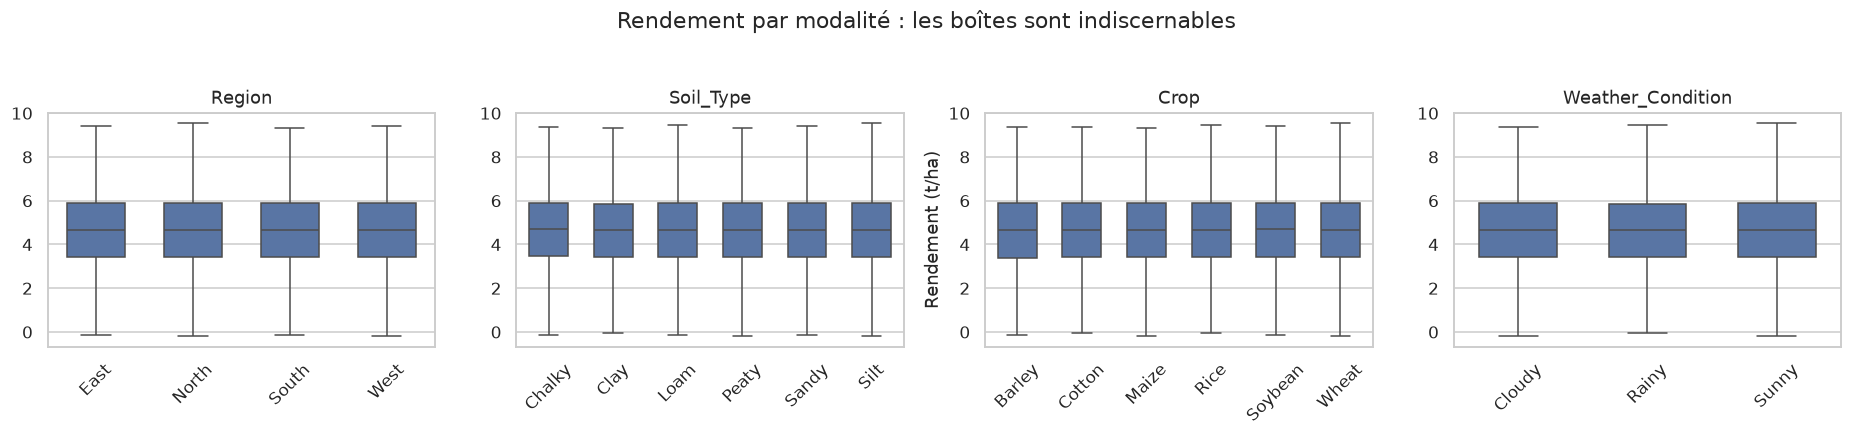

,écart max (t/ha),écart relatif
Region,0.0085,0.0018
Soil_Type,0.0080,0.0017
Crop,0.0123,0.0027
Weather_Condition,0.0047,0.0010


In [16]:
categorielles = list(preparation.COLONNES_CATEGORIELLES)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, colonne in zip(axes, categorielles):
    sns.boxplot(data=echantillon, x=colonne, y=preparation.CIBLE, ax=ax,
                showfliers=False, width=0.6)
    ax.set_title(colonne)
    ax.set_xlabel("")
    ax.set_ylabel("Rendement (t/ha)" if colonne == "Crop" else "")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Rendement par modalité : les boîtes sont indiscernables", y=1.04)
utils.enregistre("01_categorielles_sans_signal")
plt.show()

resume = pd.DataFrame({
    colonne: {
        "écart max (t/ha)": (m := df.groupby(colonne, observed=True)[preparation.CIBLE].mean()).max() - m.min(),
        "écart relatif": (m.max() - m.min()) / m.mean(),
    }
    for colonne in categorielles
}).T
resume.round(4)

**Observations :**

- Les quatre variables nominales n'expliquent rien : **0,2 % d'écart au maximum** entre
  modalités, soit 0,01 à 0,05 t/ha.
- En particulier, les six cultures rendent toutes ≈ 4,65 t/ha. Combiné aux interactions
  ci-dessus, cela signifie que **dans ce jeu, ce que l'on plante ne change rien**.

# Cohérence des données

In [17]:
# Is the reported weather related to the measured rainfall and temperature?
print(df.groupby("Weather_Condition", observed=True)["Rainfall_mm"]
      .agg(["mean", "min", "max"]).round(1).to_string())
print()
print(df.groupby("Weather_Condition", observed=True)["Temperature_Celsius"]
      .mean().round(2).to_string())

                    mean    min     max
Weather_Condition                      
Cloudy             549.5  100.0  1000.0
Rainy              550.1  100.0  1000.0
Sunny              550.3  100.0  1000.0

Weather_Condition
Cloudy    27.52
Rainy     27.49
Sunny     27.50


**Observations :**

- Pluie moyenne quasi identique selon la météo déclarée (**549,5 / 550,1 / 550,3 mm**),
  même plage de 100 à 1000 mm, et 27,5 °C dans les trois cas.
- `Weather_Condition` se comporte donc comme si elle avait été **tirée indépendamment**
  de la pluie et de la température — ce qui est cohérent avec une génération synthétique
  et la rend inexploitable en l'état.
- Cela ne permet pas d'affirmer qu'une ligne « Sunny » très arrosée serait impossible,
  seulement que la colonne ne porte pas d'information.

# Conclusion

## Ce que contient le jeu de données
1 000 000 de lignes, 10 colonnes, **aucune valeur manquante, aucun doublon**. Modalités
parfaitement équilibrées et variables explicatives uniformes : le jeu est **simulé**.

## Ce qui explique le rendement

| Variable | Effet |
|---|---|
| `Rainfall_mm` | le plus fort — corrélation 0,765, relation droite |
| `Fertilizer_Used` | **+1,50 t/ha** en moyenne |
| `Irrigation_Used` | **+1,20 t/ha** en moyenne |

Malgré une corrélation faible (0,086), `Temperature_Celsius` fait apparaître par tranches
une progression **régulière et sans exception**, de **+0,445 t/ha** du plus froid au plus
chaud. L'effet est faible mais systématique.

*Sur les interactions testées, les effets de la pluie, de l'engrais et de l'irrigation
sont très similaires d'une culture à l'autre.*

## Ce pour quoi aucune relation n'apparaît
- `Region`, `Soil_Type`, `Crop` et `Weather_Condition` : **0,2 % d'écart au maximum**
  entre modalités. Les cultures restent équivalentes à conditions comparables, sur les
  croisements examinés.
- `Days_to_Harvest` : ni relation droite (−0,004), ni par tranches (0,028 t/ha).
- `Weather_Condition` apparaît de plus indépendante de la pluie et de la température.

## Les points de qualité à traiter
- **231 rendements négatifs** (0,023 %), tous sans engrais ni irrigation, et 223 sur 231
  sous 200 mm de pluie.
- Deux booléens stockés en texte.
- `Weather_Condition` n'apporte aucune information exploitable en l'état.

## Décisions à confirmer plus tard
- Que faire des 231 rendements négatifs : conserver, ramener à 0, ou supprimer ?
- Garder ou écarter `Days_to_Harvest`, pour lequel aucune relation n'apparaît ?
- Garder les quatre variables nominales, alors qu'aucune ne se relie au rendement ?
- Garder `Temperature_Celsius`, dont l'effet est faible mais régulier ? Les tranches
  plaident pour la conserver.

## Hypothèses à vérifier plus tard
- Une régression linéaire devrait déjà bien fonctionner : la relation à la pluie est
  droite et les effets semblent s'additionner.
- L'absence d'effet de la culture, **y compris à conditions égales**, rendra `/recommend`
  inopérant avec ce seul jeu.
- Le second jeu (CropYield Prediction) permettra de vérifier si la culture a un effet
  ailleurs — c'est l'objet des notebooks 03 à 05.